In [1]:
import json, re, uuid
from google.colab import files

# ---------- SETTINGS ----------
N_SENTENCES = 300
TEXT_KEY = None          # None = auto-detect (e.g. "text"); or set manually
LABELED_OUT = "labeled_300.json"
UNLABELED_OUT = "unlabeled_300.json"

# ---------- 1. UPLOAD ----------
uploaded = files.upload()
in_path = list(uploaded.keys())[0]
with open(in_path, encoding="utf-8") as f:
    tasks = json.load(f)
print("Tasks in file:", len(tasks))

# ---------- 2. SENTENCE SPLITTER (keeps character offsets) ----------
def sentence_spans(text):
    spans = []
    for m in re.finditer(r"[^.!?।\n]+[.!?।]*", text):
        s, e = m.start(), m.end()
        # trim whitespace but keep offsets exact
        while s < e and text[s].isspace(): s += 1
        while e > s and text[e-1].isspace(): e -= 1
        if e > s:
            spans.append((s, e))
    return spans

def get_text(data):
    key = TEXT_KEY
    if key is None:
        key = next((k for k, v in data.items() if isinstance(v, str)), None)
    return key, data.get(key, "")

# ---------- 3. BUILD SENTENCE-LEVEL TASKS ----------
labeled, unlabeled = [], []
count = 0

for task in tasks:
    if count >= N_SENTENCES:
        break
    key, text = get_text(task.get("data", {}))
    if not text:
        continue

    # collect all annotation results (first annotation only; change if needed)
    anns = task.get("annotations") or task.get("completions") or []
    results = anns[0].get("result", []) if anns else []

    for (s, e) in sentence_spans(text):
        if count >= N_SENTENCES:
            break
        sent = text[s:e]
        new_results = []

        for r in results:
            v = r.get("value", {})
            if "start" in v and "end" in v:              # NER / span labels
                if v["start"] >= s and v["end"] <= e:    # span fully inside sentence
                    nv = dict(v)
                    nv["start"] = v["start"] - s
                    nv["end"] = v["end"] - s
                    nv["text"] = sent[nv["start"]:nv["end"]]
                    nr = dict(r)
                    nr["value"] = nv
                    nr["id"] = uuid.uuid4().hex[:10]
                    new_results.append(nr)
            elif "choices" in v:                          # task-level classification
                new_results.append(r)                     # copied to each sentence

        sid = count + 1
        # unlabeled: only sentence text
        unlabeled.append({"id": sid, "data": {key: sent}})
        # labeled: same sentence + annotation
        labeled.append({
            "id": sid,
            "data": {key: sent},
            "annotations": [{"result": new_results}] if new_results else []
        })
        count += 1

print("Sentences extracted:", count)
print("Sentences with labels:", sum(1 for t in labeled if t["annotations"]))

# ---------- 4. SAVE + DOWNLOAD ----------
with open(LABELED_OUT, "w", encoding="utf-8") as f:
    json.dump(labeled, f, ensure_ascii=False, indent=2)
with open(UNLABELED_OUT, "w", encoding="utf-8") as f:
    json.dump(unlabeled, f, ensure_ascii=False, indent=2)

# sanity check: both files have identical sentences
assert [t["data"] for t in labeled] == [t["data"] for t in unlabeled]
print("Both files contain identical sentences ✔")

files.download(LABELED_OUT)
files.download(UNLABELED_OUT)

Saving 17entity_news_ner_dataset.json to 17entity_news_ner_dataset.json
Tasks in file: 24866
Sentences extracted: 300
Sentences with labels: 272
Both files contain identical sentences ✔


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import json
lab = json.load(open("labeled_300.json", encoding="utf-8"))
unl = json.load(open("unlabeled_300.json", encoding="utf-8"))

for t in lab[:3]:
    print(t["data"])
    for r in t["annotations"][0]["result"] if t["annotations"] else []:
        v = r["value"]
        print("   ", v["text"], "->", v.get("labels"))
    print()

{'text': 'In the 2024 presidential election , you could vote for Kamala Harris on the Democratic line or on the Working Families Party line .'}
    2024 -> ['DATE']
    Kamala Harris -> ['PER']
    Democratic -> ['NORP']
    Working Families Party -> ['ORG']

{'text': 'And the Working Families Party is a vibrant third party in New York .'}
    Working Families Party -> ['ORG']
    third -> ['ORD']
    New York -> ['LOC']

{'text': 'And actually , we just put out a great paper at New America on the Working Families Party as an associational party , by Tabatha Abu El - Haj , who ’s a great election law scholar of parties .'}
    New America -> ['LOC']
     Working Families Party -> ['ORG']
    Tabatha Abu El - Haj -> ['PER']



In [3]:
import json
import pandas as pd
from collections import Counter

LABELED = "labeled_300.json"
UNLABELED = "unlabeled_300.json"

lab = json.load(open(LABELED, encoding="utf-8"))
unl = json.load(open(UNLABELED, encoding="utf-8"))

def text_of(t):
    return next(iter(t["data"].values()))

# ---------- 1. BASIC CHECKS ----------
print("=" * 50)
print("FILE CHECK")
print("=" * 50)
print("Labeled sentences   :", len(lab))
print("Unlabeled sentences :", len(unl))
same = [text_of(a) for a in lab] == [text_of(b) for b in unl]
print("Same sentences, same order:", same)

unl_with_ann = sum(1 for t in unl if t.get("annotations"))
print("Unlabeled file sentences having annotations:", unl_with_ann, "(should be 0)")

# ---------- 2. PER-SENTENCE TABLE ----------
rows = []
tag_counter = Counter()

for t in lab:
    sent = text_of(t)
    results = t["annotations"][0]["result"] if t.get("annotations") else []
    tags = []
    for r in results:
        v = r["value"]
        if "labels" in v:
            tags.extend(v["labels"])
    tag_counter.update(tags)
    rows.append({
        "id": t["id"],
        "sentence": sent,
        "n_chars": len(sent),
        "n_words": len(sent.split()),
        "n_tags": len(results),
        "tag_types": ", ".join(sorted(set(tags))),
    })

df = pd.DataFrame(rows)

# ---------- 3. SENTENCE LENGTH ----------
print("\n" + "=" * 50)
print("SENTENCE LENGTH")
print("=" * 50)
print(df[["n_words", "n_chars"]].describe().round(1))
print("\nShortest sentence:", df.loc[df.n_words.idxmin(), "sentence"][:100])
print("Longest sentence :", df.loc[df.n_words.idxmax(), "sentence"][:100], "...")

# ---------- 4. TAGS PER SENTENCE ----------
print("\n" + "=" * 50)
print("TAGS PER SENTENCE")
print("=" * 50)
print("Total tags (entities):", int(df.n_tags.sum()))
print("Sentences with >=1 tag:", int((df.n_tags > 0).sum()))
print("Sentences with 0 tags :", int((df.n_tags == 0).sum()))
print("Average tags per sentence:", round(df.n_tags.mean(), 2))
print("Max tags in one sentence :", int(df.n_tags.max()))
print("\nHow many sentences have how many tags:")
print(df.n_tags.value_counts().sort_index().rename("n_sentences").to_frame())

# ---------- 5. TAG TYPE COUNTS ----------
print("\n" + "=" * 50)
print("TAG TYPE COUNTS")
print("=" * 50)
tag_df = pd.DataFrame(tag_counter.most_common(), columns=["tag", "count"])
print(tag_df.to_string(index=False))

# ---------- 6. SAVE REPORT ----------
df.to_csv("sentence_report.csv", index=False, encoding="utf-8-sig")
tag_df.to_csv("tag_counts.csv", index=False)
print("\nSaved: sentence_report.csv, tag_counts.csv")

# Optional: download
# from google.colab import files
# files.download("sentence_report.csv"); files.download("tag_counts.csv")

FILE CHECK
Labeled sentences   : 300
Unlabeled sentences : 300
Same sentences, same order: True
Unlabeled file sentences having annotations: 0 (should be 0)

SENTENCE LENGTH
       n_words  n_chars
count    300.0    300.0
mean      32.1    177.0
std       16.1     90.5
min        1.0      1.0
25%       21.0    115.0
50%       30.0    169.0
75%       42.0    231.5
max       88.0    480.0

Shortest sentence: S.
Longest sentence : Ultimately , what is happening in the UK — the rapid rise and fall of mediocre leaders , the degrada ...

TAGS PER SENTENCE
Total tags (entities): 914
Sentences with >=1 tag: 272
Sentences with 0 tags : 28
Average tags per sentence: 3.05
Max tags in one sentence : 11

How many sentences have how many tags:
        n_sentences
n_tags             
0                28
1                40
2                65
3                61
4                41
5                31
6                12
7                11
8                 8
9                 2
11                1


In [4]:
short = df[df.n_words <= 3]
print(short[["id", "sentence", "n_tags"]].to_string(index=False))

 id  sentence  n_tags
 22    The U.       0
 23        S.       0
 66 In the U.       0
 67        S.       0
 77        S.       0
 87        S.       0
 91        S.       0
165         "       0
174        S.       0
180  Under U.       0
181        K.       0
186        K.       0
221   Nepal .       0
227         ”       0
238        S.       0
256        D.       0


In [6]:
import json, re, uuid, random
from google.colab import files   # still needed for the final download

# ---------- SETTINGS ----------
IN_PATH     = "17entity_news_ner_dataset.json"   # already uploaded, no files.upload()
N_SENTENCES = 300
MIN_WORDS   = 3
SHUFFLE     = True
SEED        = 42
TEXT_KEY    = None
LABELED_OUT   = "labeled_300.json"
UNLABELED_OUT = "unlabeled_300.json"

# ---------- 1. LOAD ----------
with open(IN_PATH, encoding="utf-8") as f:
    tasks = json.load(f)
print("Tasks in file:", len(tasks))

if SHUFFLE:
    random.seed(SEED)
    random.shuffle(tasks)

# ---------- 2. SENTENCE SPLITTER (abbreviation-safe, offsets preserved) ----------
DOT = "\u2024"  # one-character stand-in for "." (same length -> offsets stay valid)
ABBR = ["Mr.", "Mrs.", "Ms.", "Dr.", "St.", "Jr.", "Sr.", "Inc.", "Corp.", "Co.",
        "Ltd.", "No.", "Gen.", "Sen.", "Rep.", "Gov.", "Lt.", "Col.", "Prof.",
        "Mt.", "vs.", "etc.", "Sgt.", "Capt.", "Rev."]
ABBR_RE = re.compile(r"(?<![A-Za-z])(?:" + "|".join(re.escape(a) for a in ABBR) + ")")
DOTTED_RE  = re.compile(r"\b(?:[A-Za-z]\.){2,}")        # U.S.  U.K.  D.C.  a.m.
INITIAL_RE = re.compile(r"\b[A-Z]\.(?=\s*[A-Z])")        # J. Smith
SPLIT_RE   = re.compile(r"[^.!?।\n]+(?:[.!?।]+[\"”’')\]]*)?")

def mask(text):
    for rx in (DOTTED_RE, ABBR_RE, INITIAL_RE):
        text = rx.sub(lambda m: m.group(0).replace(".", DOT), text)
    return text

def sentence_spans(text):
    masked = mask(text)
    spans = []
    for m in SPLIT_RE.finditer(masked):
        s, e = m.start(), m.end()
        while s < e and text[s].isspace(): s += 1
        while e > s and text[e-1].isspace(): e -= 1
        if e <= s:
            continue
        # fragment with no letters/digits (e.g. a lone quote) -> glue to previous
        if not re.search(r"\w", text[s:e]) and spans:
            spans[-1] = (spans[-1][0], e)
        else:
            spans.append((s, e))
    return spans

def get_text(data):
    key = TEXT_KEY or next((k for k, v in data.items() if isinstance(v, str)), None)
    return key, data.get(key, "")

# ---------- 3. BUILD SENTENCE-LEVEL TASKS ----------
labeled, unlabeled = [], []
count = 0

for task in tasks:
    if count >= N_SENTENCES:
        break
    key, text = get_text(task.get("data", {}))
    if not text:
        continue

    anns = task.get("annotations") or task.get("completions") or []
    results = anns[0].get("result", []) if anns else []

    for (s, e) in sentence_spans(text):
        if count >= N_SENTENCES:
            break
        sent = text[s:e]
        if len(sent.split()) < MIN_WORDS:
            continue

        new_results = []
        for r in results:
            v = r.get("value", {})
            if "start" in v and "end" in v:
                if v["start"] >= s and v["end"] <= e:
                    nv = dict(v)
                    ns, ne = v["start"] - s, v["end"] - s
                    seg = sent[ns:ne]
                    ns += len(seg) - len(seg.lstrip())      # trim leading space
                    ne -= len(seg) - len(seg.rstrip())      # trim trailing space
                    if ne <= ns:
                        continue
                    nv["start"], nv["end"] = ns, ne
                    nv["text"] = sent[ns:ne]
                    nr = dict(r)
                    nr["value"] = nv
                    nr["id"] = uuid.uuid4().hex[:10]
                    new_results.append(nr)
            elif "choices" in v:
                new_results.append(r)

        sid = count + 1
        unlabeled.append({"id": sid, "data": {key: sent}})
        labeled.append({
            "id": sid,
            "data": {key: sent},
            "annotations": [{"result": new_results}] if new_results else []
        })
        count += 1

print("Sentences extracted:", count)
print("Sentences with labels:", sum(1 for t in labeled if t["annotations"]))

# ---------- 4. SAVE + DOWNLOAD ----------
with open(LABELED_OUT, "w", encoding="utf-8") as f:
    json.dump(labeled, f, ensure_ascii=False, indent=2)
with open(UNLABELED_OUT, "w", encoding="utf-8") as f:
    json.dump(unlabeled, f, ensure_ascii=False, indent=2)

assert [t["data"] for t in labeled] == [t["data"] for t in unlabeled]
print("Both files contain identical sentences ✔")

files.download(LABELED_OUT)
files.download(UNLABELED_OUT)

Tasks in file: 24866
Sentences extracted: 300
Sentences with labels: 270
Both files contain identical sentences ✔


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import json
lab = json.load(open("labeled_300.json", encoding="utf-8"))
unl = json.load(open("unlabeled_300.json", encoding="utf-8"))

for t in lab[:3]:
    print(t["data"])
    for r in t["annotations"][0]["result"] if t["annotations"] else []:
        v = r["value"]
        print("   ", v["text"], "->", v.get("labels"))
    print()

{'text': "An imaginative novelist writing a thriller about amateur spy - chasing might invent a Clifford Stoll , but it 's unlikely ."}
    a Clifford Stoll -> ['PER']

{'text': "The summit concluded with optimism regarding India's fintech future."}
    India -> ['LOC']

{'text': 'Karnataka strengthened its position as a hub for logistics technology and digital-supply-chain innovation.'}
    Karnataka -> ['LOC']



In [8]:
import json
import pandas as pd
from collections import Counter

LABELED = "labeled_300.json"
UNLABELED = "unlabeled_300.json"

lab = json.load(open(LABELED, encoding="utf-8"))
unl = json.load(open(UNLABELED, encoding="utf-8"))

def text_of(t):
    return next(iter(t["data"].values()))

# ---------- 1. BASIC CHECKS ----------
print("=" * 50)
print("FILE CHECK")
print("=" * 50)
print("Labeled sentences   :", len(lab))
print("Unlabeled sentences :", len(unl))
same = [text_of(a) for a in lab] == [text_of(b) for b in unl]
print("Same sentences, same order:", same)

unl_with_ann = sum(1 for t in unl if t.get("annotations"))
print("Unlabeled file sentences having annotations:", unl_with_ann, "(should be 0)")

# ---------- 2. PER-SENTENCE TABLE ----------
rows = []
tag_counter = Counter()

for t in lab:
    sent = text_of(t)
    results = t["annotations"][0]["result"] if t.get("annotations") else []
    tags = []
    for r in results:
        v = r["value"]
        if "labels" in v:
            tags.extend(v["labels"])
    tag_counter.update(tags)
    rows.append({
        "id": t["id"],
        "sentence": sent,
        "n_chars": len(sent),
        "n_words": len(sent.split()),
        "n_tags": len(results),
        "tag_types": ", ".join(sorted(set(tags))),
    })

df = pd.DataFrame(rows)

# ---------- 3. SENTENCE LENGTH ----------
print("\n" + "=" * 50)
print("SENTENCE LENGTH")
print("=" * 50)
print(df[["n_words", "n_chars"]].describe().round(1))
print("\nShortest sentence:", df.loc[df.n_words.idxmin(), "sentence"][:100])
print("Longest sentence :", df.loc[df.n_words.idxmax(), "sentence"][:100], "...")

# ---------- 4. TAGS PER SENTENCE ----------
print("\n" + "=" * 50)
print("TAGS PER SENTENCE")
print("=" * 50)
print("Total tags (entities):", int(df.n_tags.sum()))
print("Sentences with >=1 tag:", int((df.n_tags > 0).sum()))
print("Sentences with 0 tags :", int((df.n_tags == 0).sum()))
print("Average tags per sentence:", round(df.n_tags.mean(), 2))
print("Max tags in one sentence :", int(df.n_tags.max()))
print("\nHow many sentences have how many tags:")
print(df.n_tags.value_counts().sort_index().rename("n_sentences").to_frame())

# ---------- 5. TAG TYPE COUNTS ----------
print("\n" + "=" * 50)
print("TAG TYPE COUNTS")
print("=" * 50)
tag_df = pd.DataFrame(tag_counter.most_common(), columns=["tag", "count"])
print(tag_df.to_string(index=False))

# ---------- 6. SAVE REPORT ----------
df.to_csv("sentence_report.csv", index=False, encoding="utf-8-sig")
tag_df.to_csv("tag_counts.csv", index=False)
print("\nSaved: sentence_report.csv, tag_counts.csv")

# Optional: download
# from google.colab import files
# files.download("sentence_report.csv"); files.download("tag_counts.csv")

FILE CHECK
Labeled sentences   : 300
Unlabeled sentences : 300
Same sentences, same order: True
Unlabeled file sentences having annotations: 0 (should be 0)

SENTENCE LENGTH
       n_words  n_chars
count    300.0    300.0
mean      23.4    131.7
std       14.0     74.4
min        3.0     11.0
25%       12.0     81.0
50%       22.0    120.5
75%       31.0    176.5
max       77.0    425.0

Shortest sentence: 8 percent .
Longest sentence : “ Now he can be re - elected as many times as he wants , and people are being told that if another g ...

TAGS PER SENTENCE
Total tags (entities): 802
Sentences with >=1 tag: 270
Sentences with 0 tags : 30
Average tags per sentence: 2.67
Max tags in one sentence : 15

How many sentences have how many tags:
        n_sentences
n_tags             
0                30
1                80
2                52
3                50
4                39
5                24
6                11
7                 3
8                 6
9                 1
10         

In [9]:
import json
import pandas as pd
from collections import Counter
from openpyxl.styles import PatternFill, Font, Alignment
from openpyxl.utils import get_column_letter
from google.colab import files

IN_PATH, OUT_PATH = "labeled_300.json", "labeled_300.xlsx"
lab = json.load(open(IN_PATH, encoding="utf-8"))

# ---------- build rows ----------
sent_rows, ent_rows = [], []
for t in lab:
    text = next(iter(t["data"].values()))
    res = t["annotations"][0]["result"] if t.get("annotations") else []
    res = sorted([r for r in res if "labels" in r["value"]], key=lambda r: r["value"]["start"])

    tagged, pos = "", 0
    for r in res:
        v = r["value"]
        ent_rows.append({"ID": t["id"], "Entity": v["text"].strip(), "Tag": v["labels"][0],
                         "Start": v["start"], "End": v["end"], "Sentence": text})
        if v["start"] < pos:          # skip overlaps in the inline view
            continue
        tagged += text[pos:v["start"]] + f"[{text[v['start']:v['end']]} | {v['labels'][0]}]"
        pos = v["end"]
    tagged += text[pos:]

    sent_rows.append({
        "ID": t["id"],
        "Sentence": text,
        "Tagged Sentence": tagged,
        "Entities": "; ".join(f"{r['value']['text'].strip()} ({r['value']['labels'][0]})" for r in res),
        "Words": len(text.split()),
        "Tags": len(res),
    })

df_s = pd.DataFrame(sent_rows)
df_e = pd.DataFrame(ent_rows)
df_t = pd.DataFrame(Counter(df_e["Tag"]).most_common(), columns=["Tag", "Count"])
df_t["Percent"] = (df_t["Count"] / df_t["Count"].sum() * 100).round(1)

# ---------- write + style ----------
palette = ["F8CBAD","FFE699","C6E0B4","BDD7EE","D9C3E8","F4B6C2","B7E1E0","E2EFDA","FCE4D6",
           "DDEBF7","FFF2CC","D0CECE","C9E4DE","F7D9C4","DBCDF0","FADADD","E6EE9C"]
tag_color = {tag: palette[i % len(palette)] for i, tag in enumerate(sorted(df_e["Tag"].unique()))}

with pd.ExcelWriter(OUT_PATH, engine="openpyxl") as xw:
    df_s.to_excel(xw, "Sentences", index=False)
    df_e.to_excel(xw, "Entities", index=False)
    df_t.to_excel(xw, "Tag Summary", index=False)

    widths = {"Sentences": [6, 70, 80, 45, 8, 8],
              "Entities": [6, 30, 10, 8, 8, 80],
              "Tag Summary": [12, 10, 10]}
    for name, ws in xw.sheets.items():
        for c in ws[1]:                                   # header
            c.fill = PatternFill("solid", fgColor="1F4E78")
            c.font = Font(bold=True, color="FFFFFF")
            c.alignment = Alignment(horizontal="center", vertical="center")
        for i, w in enumerate(widths[name], 1):
            ws.column_dimensions[get_column_letter(i)].width = w
        for row in ws.iter_rows(min_row=2):               # body
            for c in row:
                c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        if name in ("Entities", "Tag Summary"):           # colour the Tag column
            for row in ws.iter_rows(min_row=2, max_col=3):
                for c in row:
                    if c.value in tag_color:
                        c.fill = PatternFill("solid", fgColor=tag_color[c.value])
                        c.font = Font(bold=True)

print("Saved:", OUT_PATH)
files.download(OUT_PATH)

/tmp/ipykernel_2623/1169580054.py:49: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  df_s.to_excel(xw, "Sentences", index=False)
/tmp/ipykernel_2623/1169580054.py:50: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  df_e.to_excel(xw, "Entities", index=False)
/tmp/ipykernel_2623/1169580054.py:51: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  df_t.to_excel(xw, "Tag Summary", index=False)


Saved: labeled_300.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import json, re, random
import numpy as np
from collections import Counter
from sklearn.metrics import cohen_kappa_score

A_PATH = "labeled_300.json"          # annotator 1 (original labels)
B_PATH = "annotator2_export.json"    # annotator 2 (new, independent)

def load(p): return json.load(open(p, encoding="utf-8"))
def text_of(t): return next(iter(t["data"].values()))

# ---------- 1. spans -> token-level BIO ----------
def to_bio(task):
    text = text_of(task)
    toks = [(m.start(), m.end()) for m in re.finditer(r"\S+", text)]
    tags = ["O"] * len(toks)
    anns = task.get("annotations") or []
    res = anns[0].get("result", []) if anns else []
    spans = []
    for r in sorted(res, key=lambda r: r["value"].get("start", 0)):
        v = r["value"]
        if "labels" not in v:
            continue
        spans.append((v["start"], v["end"], v["labels"][0]))
        first = True
        for i, (s, e) in enumerate(toks):
            if s < v["end"] and e > v["start"]:
                tags[i] = ("B-" if first else "I-") + v["labels"][0]
                first = False
    return tags, spans

# ---------- 2. align the two files by sentence text ----------
A, B = load(A_PATH), load(B_PATH)
b_by_text = {}
for t in B:
    b_by_text.setdefault(text_of(t).strip(), []).append(t)

pairs, missing = [], 0
for a in A:
    cand = b_by_text.get(text_of(a).strip())
    if cand:
        pairs.append((a, cand.pop(0)))
    else:
        missing += 1
print(f"Aligned sentences: {len(pairs)} | not found in annotator 2 file: {missing}")

# ---------- 3. build tag sequences ----------
sent_a, sent_b, spans_a, spans_b = [], [], [], []
for a, b in pairs:
    ta, sa = to_bio(a); tb, sb = to_bio(b)
    assert len(ta) == len(tb)
    sent_a.append(ta); sent_b.append(tb); spans_a.append(sa); spans_b.append(sb)

def flat(seqs): return [t for s in seqs for t in s]
strip = lambda tags: [t.split("-", 1)[-1] if t != "O" else "O" for t in tags]

def kappa_for(idx):
    a = flat([sent_a[i] for i in idx]); b = flat([sent_b[i] for i in idx])
    return a, b

all_idx = list(range(len(pairs)))
a, b = kappa_for(all_idx)

# ---------- 4. kappa variants ----------
print("\n=== TOKEN-LEVEL COHEN'S KAPPA ===")
print("Total tokens compared:", len(a))
print("Kappa (BIO tags, all tokens)     :", round(cohen_kappa_score(a, b), 4))
print("Kappa (entity type, all tokens)  :", round(cohen_kappa_score(strip(a), strip(b)), 4))
keep = [i for i in range(len(a)) if not (a[i] == "O" and b[i] == "O")]
print("Kappa (entity type, ignoring O-O):", round(cohen_kappa_score(
      [strip(a)[i] for i in keep], [strip(b)[i] for i in keep]), 4))
print("Raw token agreement              :", round(np.mean(np.array(a) == np.array(b)), 4))

# ---------- 5. bootstrap 95% CI (resample sentences) ----------
random.seed(42)
boots = []
for _ in range(1000):
    idx = [random.choice(all_idx) for _ in all_idx]
    x, y = kappa_for(idx)
    boots.append(cohen_kappa_score(x, y))
print("95% CI (BIO kappa):", np.round(np.percentile(boots, [2.5, 97.5]), 4))

# ---------- 6. per-entity-type kappa ----------
print("\n=== PER-TAG KAPPA (binary: tag vs not-tag) ===")
sa_, sb_ = strip(a), strip(b)
for tag in sorted(set(sa_ + sb_) - {"O"}):
    ba = [int(x == tag) for x in sa_]; bb = [int(x == tag) for x in sb_]
    k = cohen_kappa_score(ba, bb) if len(set(ba + bb)) > 1 else float("nan")
    print(f"{tag:6s} kappa={k:.3f}  (A tokens={sum(ba)}, B tokens={sum(bb)})")

# ---------- 7. entity-level exact-match agreement ----------
SA = {(i, s, e, l) for i, sp in enumerate(spans_a) for s, e, l in sp}
SB = {(i, s, e, l) for i, sp in enumerate(spans_b) for s, e, l in sp}
tp = len(SA & SB)
p, r = tp / max(len(SB), 1), tp / max(len(SA), 1)
f1 = 2 * p * r / max(p + r, 1e-9)
print("\n=== ENTITY-LEVEL (exact span + label match) ===")
print(f"Entities A={len(SA)}  B={len(SB)}  matched={tp}")
print(f"Precision={p:.3f}  Recall={r:.3f}  F1={f1:.3f}")

# ---------- 8. disagreements to review ----------
dis = Counter((x, y) for x, y in zip(sa_, sb_) if x != y)
print("\nTop disagreement pairs (A -> B):")
for (x, y), c in dis.most_common(10):
    print(f"  {x:6s} -> {y:6s}: {c}")

Aligned sentences: 300 | not found in annotator 2 file: 0

=== TOKEN-LEVEL COHEN'S KAPPA ===
Total tokens compared: 7010
Kappa (BIO tags, all tokens)     : 0.8868
Kappa (entity type, all tokens)  : 0.9109
Kappa (entity type, ignoring O-O): 0.8299
Raw token agreement              : 0.9578
95% CI (BIO kappa): [0.8643 0.9062]

=== PER-TAG KAPPA (binary: tag vs not-tag) ===
CARD   kappa=0.833  (A tokens=64, B tokens=51)
DATE   kappa=0.938  (A tokens=198, B tokens=202)
EVT    kappa=0.915  (A tokens=29, B tokens=30)
FAC    kappa=0.818  (A tokens=13, B tokens=9)
LANG   kappa=1.000  (A tokens=4, B tokens=4)
LAW    kappa=0.899  (A tokens=38, B tokens=42)
LOC    kappa=0.922  (A tokens=266, B tokens=253)
MONEY  kappa=0.874  (A tokens=37, B tokens=43)
NORP   kappa=0.963  (A tokens=56, B tokens=54)
ORD    kappa=1.000  (A tokens=11, B tokens=11)
ORG    kappa=0.906  (A tokens=378, B tokens=362)
PCT    kappa=0.624  (A tokens=30, B tokens=53)
PER    kappa=0.951  (A tokens=236, B tokens=232)
PROD   kapp

In [12]:
# CELL 1 - imports + style (run AFTER your kappa script, uses a, b, sa_, sb_, SA, SB, boots)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, confusion_matrix

plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})

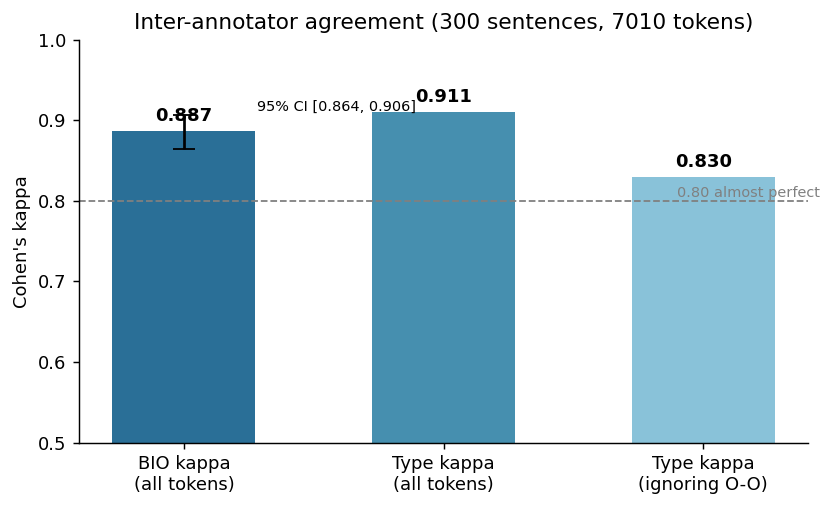

In [13]:
# CELL 2 - overall kappa variants with ci on bio kappa
keep = [i for i in range(len(a)) if not (a[i] == "O" and b[i] == "O")]
k_bio  = cohen_kappa_score(a, b)
k_type = cohen_kappa_score(sa_, sb_)
k_noO  = cohen_kappa_score([sa_[i] for i in keep], [sb_[i] for i in keep])
raw    = np.mean(np.array(a) == np.array(b))
lo, hi = np.percentile(boots, [2.5, 97.5])

names = ["BIO kappa\n(all tokens)", "Type kappa\n(all tokens)", "Type kappa\n(ignoring O-O)"]
vals  = [k_bio, k_type, k_noO]

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(names, vals, color=["#2a6f97", "#468faf", "#89c2d9"], width=0.55)
ax.errorbar(0, k_bio, yerr=[[k_bio - lo], [hi - k_bio]], fmt="none", ecolor="black", capsize=6)
for x, v in enumerate(vals):
    ax.text(x, v + 0.012, f"{v:.3f}", ha="center", fontweight="bold")
ax.text(0.28, hi + 0.005, f"95% CI [{lo:.3f}, {hi:.3f}]", fontsize=8)
ax.axhline(0.80, ls="--", c="gray", lw=1); ax.text(2.45, 0.805, "0.80 almost perfect", fontsize=8, ha="right", color="gray")
ax.set_ylim(0.5, 1.0); ax.set_ylabel("Cohen's kappa")
ax.set_title(f"Inter-annotator agreement (300 sentences, {len(a)} tokens)")
plt.tight_layout(); plt.savefig("fig1_overall_kappa.png", bbox_inches="tight"); plt.show()

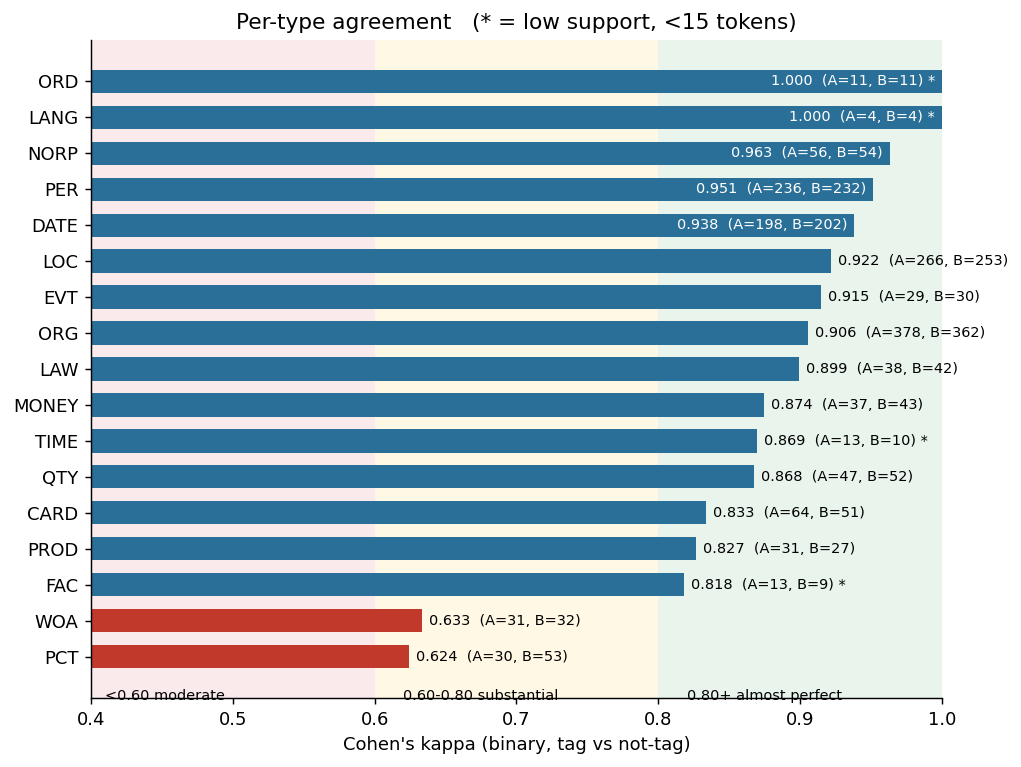

In [14]:
# CELL 3 - per-entity-type kappa (one-vs-rest) with landis-koch bands + support
tags = sorted(set(sa_ + sb_) - {"O"})
rows = []
for t in tags:
    ba = [int(x == t) for x in sa_]; bb = [int(x == t) for x in sb_]
    k = cohen_kappa_score(ba, bb) if len(set(ba + bb)) > 1 else np.nan
    rows.append((t, k, sum(ba), sum(bb)))
rows.sort(key=lambda r: r[1])

fig, ax = plt.subplots(figsize=(8, 6))
ax.axvspan(0.0, 0.60, color="#f8d7da", alpha=.5, lw=0)
ax.axvspan(0.60, 0.80, color="#fff3cd", alpha=.5, lw=0)
ax.axvspan(0.80, 1.00, color="#d4edda", alpha=.5, lw=0)
cols = ["#c0392b" if r[1] < 0.70 else "#2a6f97" for r in rows]
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=cols, height=0.65)
for i, (t, k, na, nb) in enumerate(rows):
    low = min(na, nb) < 15
    ax.text(min(k, 0.99) + 0.005 if k < 0.93 else k - 0.005, i,
            f"{k:.3f}  (A={na}, B={nb}){' *' if low else ''}",
            va="center", ha="left" if k < 0.93 else "right",
            fontsize=8, color="black" if k < 0.93 else "white")
ax.set_xlim(0.4, 1.0); ax.set_xlabel("Cohen's kappa (binary, tag vs not-tag)")
ax.set_title("Per-type agreement   (* = low support, <15 tokens)")
ax.text(0.41, -1.2, "<0.60 moderate", fontsize=8); ax.text(0.62, -1.2, "0.60-0.80 substantial", fontsize=8); ax.text(0.82, -1.2, "0.80+ almost perfect", fontsize=8)
plt.tight_layout(); plt.savefig("fig2_per_type_kappa.png", bbox_inches="tight"); plt.show()

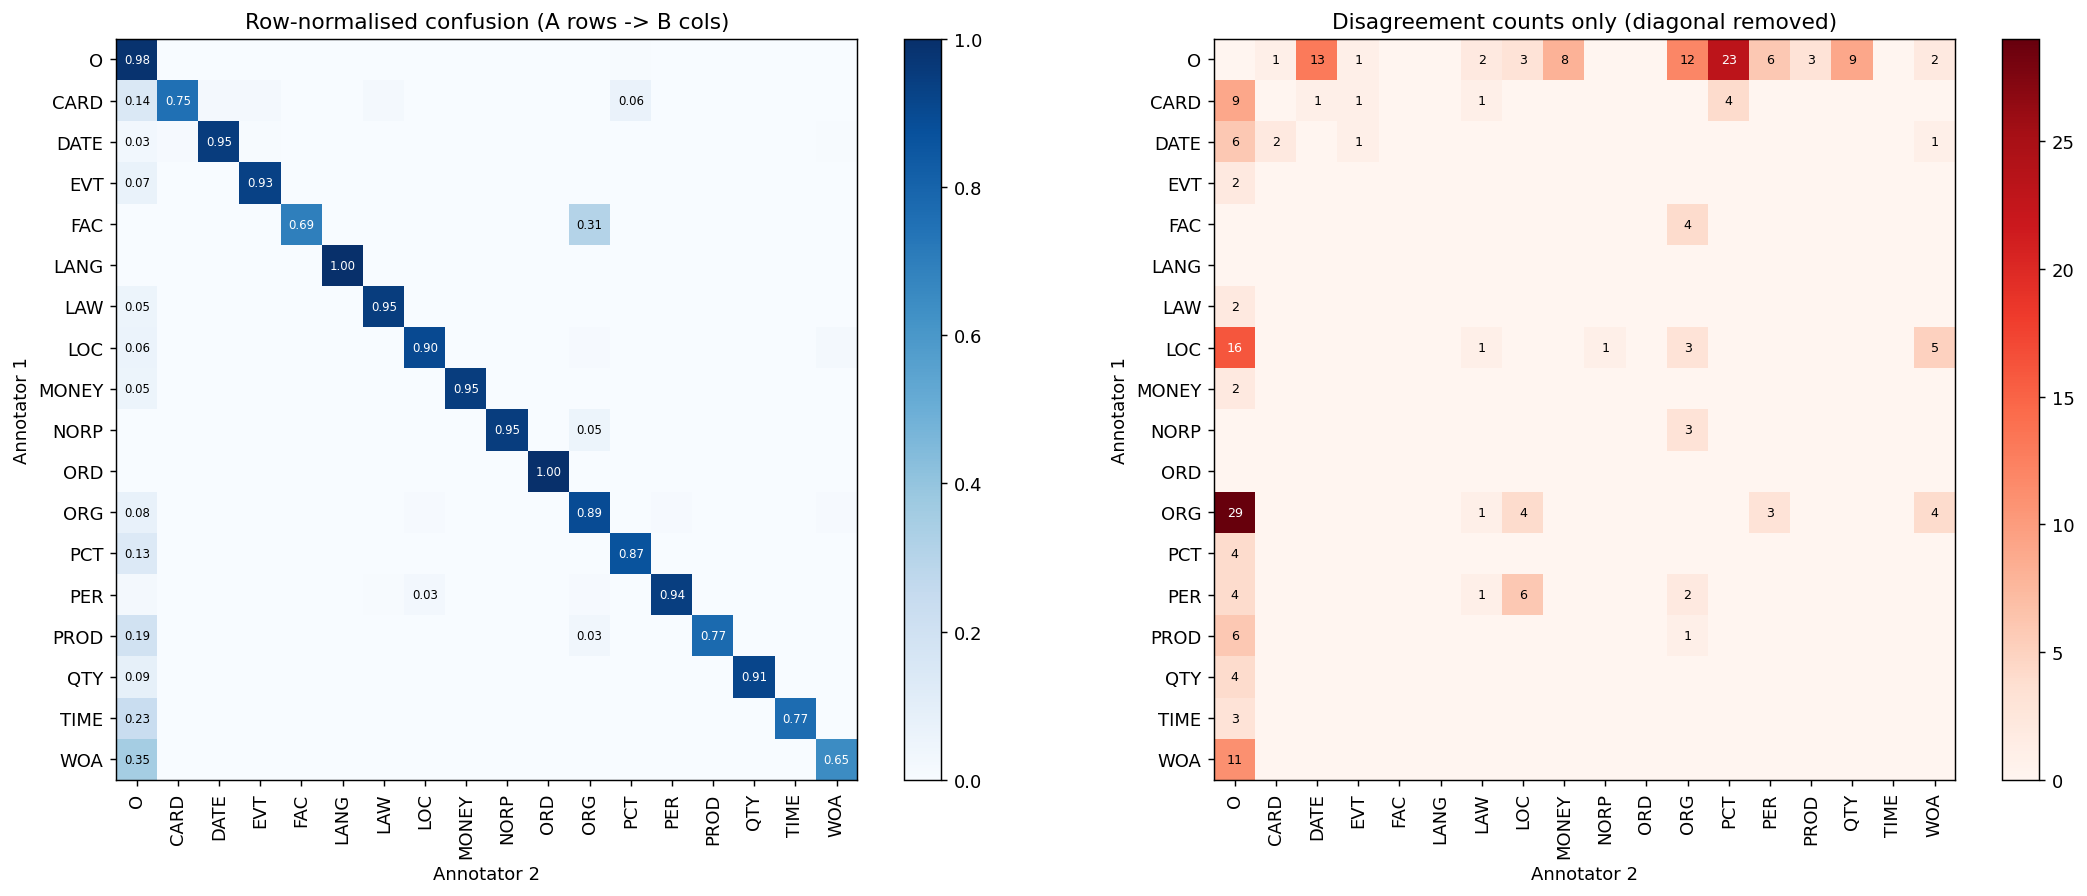

In [15]:
# CELL 4 - confusion matrix (row-normalised) + disagreement counts (no O-O)
labels = ["O"] + tags
cm = confusion_matrix(sa_, sb_, labels=labels)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
im = axes[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("Row-normalised confusion (A rows -> B cols)")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cmn[i, j] > 0.02:
            axes[0].text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=6.5,
                         color="white" if cmn[i, j] > 0.5 else "black")
plt.colorbar(im, ax=axes[0], fraction=0.046)

cm2 = cm.copy(); np.fill_diagonal(cm2, 0)     # disagreements only
im2 = axes[1].imshow(cm2, cmap="Reds")
axes[1].set_title("Disagreement counts only (diagonal removed)")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm2[i, j] > 0:
            axes[1].text(j, i, cm2[i, j], ha="center", va="center", fontsize=7,
                         color="white" if cm2[i, j] > cm2.max() * 0.5 else "black")
plt.colorbar(im2, ax=axes[1], fraction=0.046)

for ax in axes:
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Annotator 2"); ax.set_ylabel("Annotator 1")
    for s in ax.spines.values(): s.set_visible(True)
plt.tight_layout(); plt.savefig("fig3_confusion.png", bbox_inches="tight"); plt.show()

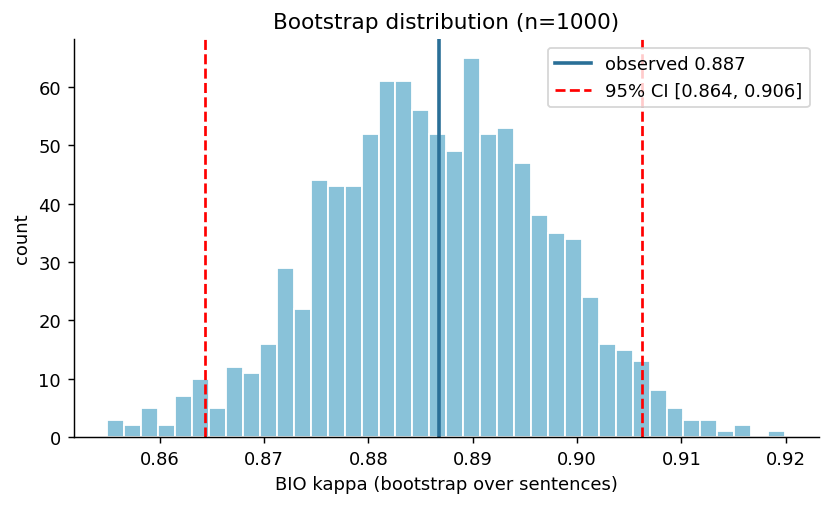

In [17]:
# CELL 5 - bootstrap distribution of kappa
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(boots, bins=40, color="#89c2d9", edgecolor="white")
ax.axvline(k_bio, c="#2a6f97", lw=2, label=f"observed {k_bio:.3f}")
ax.axvline(lo, c="red", ls="--", label=f"95% CI [{lo:.3f}, {hi:.3f}]")
ax.axvline(hi, c="red", ls="--")
ax.set_xlabel("BIO kappa (bootstrap over sentences)"); ax.set_ylabel("count")
ax.set_title("Bootstrap distribution (n=1000)"); ax.legend()
plt.tight_layout(); plt.savefig("fig4_bootstrap.png", bbox_inches="tight"); plt.show()

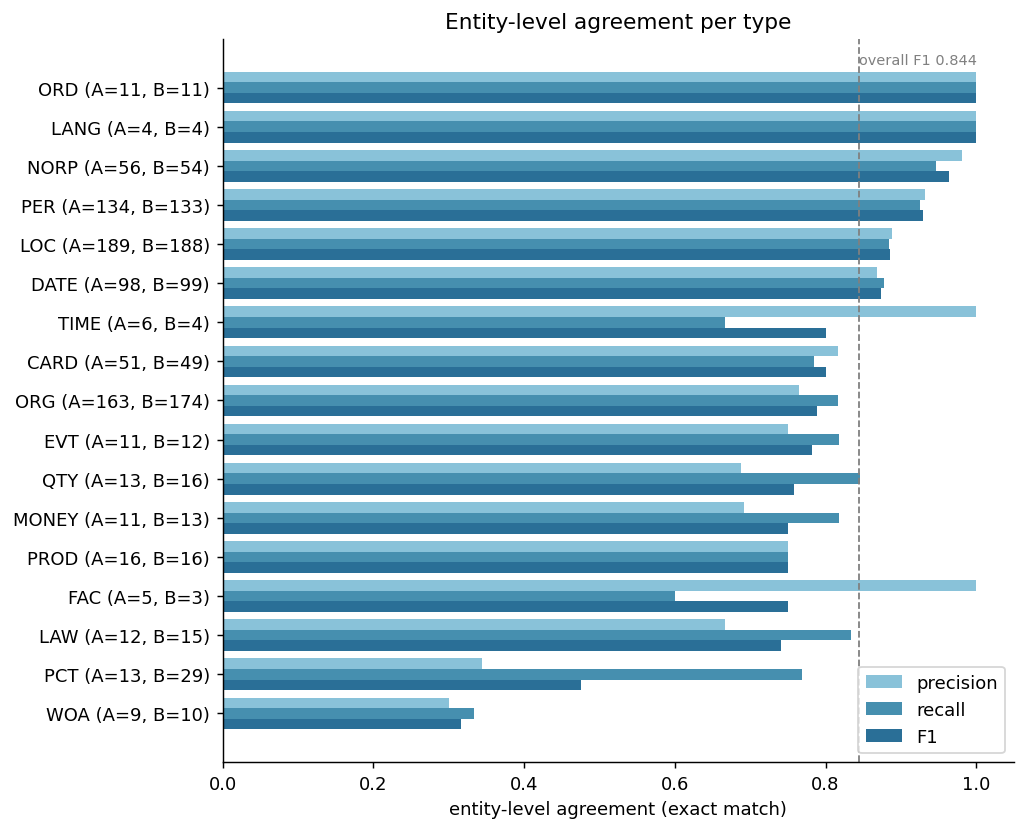

In [18]:
# CELL 5b - entity-level (exact span+label) precision / recall / f1 per type
types = sorted({l for *_, l in SA | SB})
res = []
for t in types:
    sa_t = {x for x in SA if x[3] == t}; sb_t = {x for x in SB if x[3] == t}
    tp = len(sa_t & sb_t)
    p = tp / max(len(sb_t), 1); r = tp / max(len(sa_t), 1)
    f = 2 * p * r / max(p + r, 1e-9)
    res.append((t, p, r, f, len(sa_t), len(sb_t)))
res.sort(key=lambda x: x[3])

y = np.arange(len(res)); h = 0.27
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(y + h, [r[1] for r in res], h, label="precision", color="#89c2d9")
ax.barh(y,     [r[2] for r in res], h, label="recall",    color="#468faf")
ax.barh(y - h, [r[3] for r in res], h, label="F1",        color="#2a6f97")
ax.set_yticks(y); ax.set_yticklabels([f"{r[0]} (A={r[4]}, B={r[5]})" for r in res])
ax.axvline(0.844, c="gray", ls="--", lw=1); ax.text(0.845, len(res) - 0.4, "overall F1 0.844", fontsize=8, color="gray")
ax.set_xlim(0, 1.05); ax.set_xlabel("entity-level agreement (exact match)")
ax.legend(loc="lower right"); ax.set_title("Entity-level agreement per type")
plt.tight_layout(); plt.savefig("fig5_entity_f1.png", bbox_inches="tight"); plt.show()

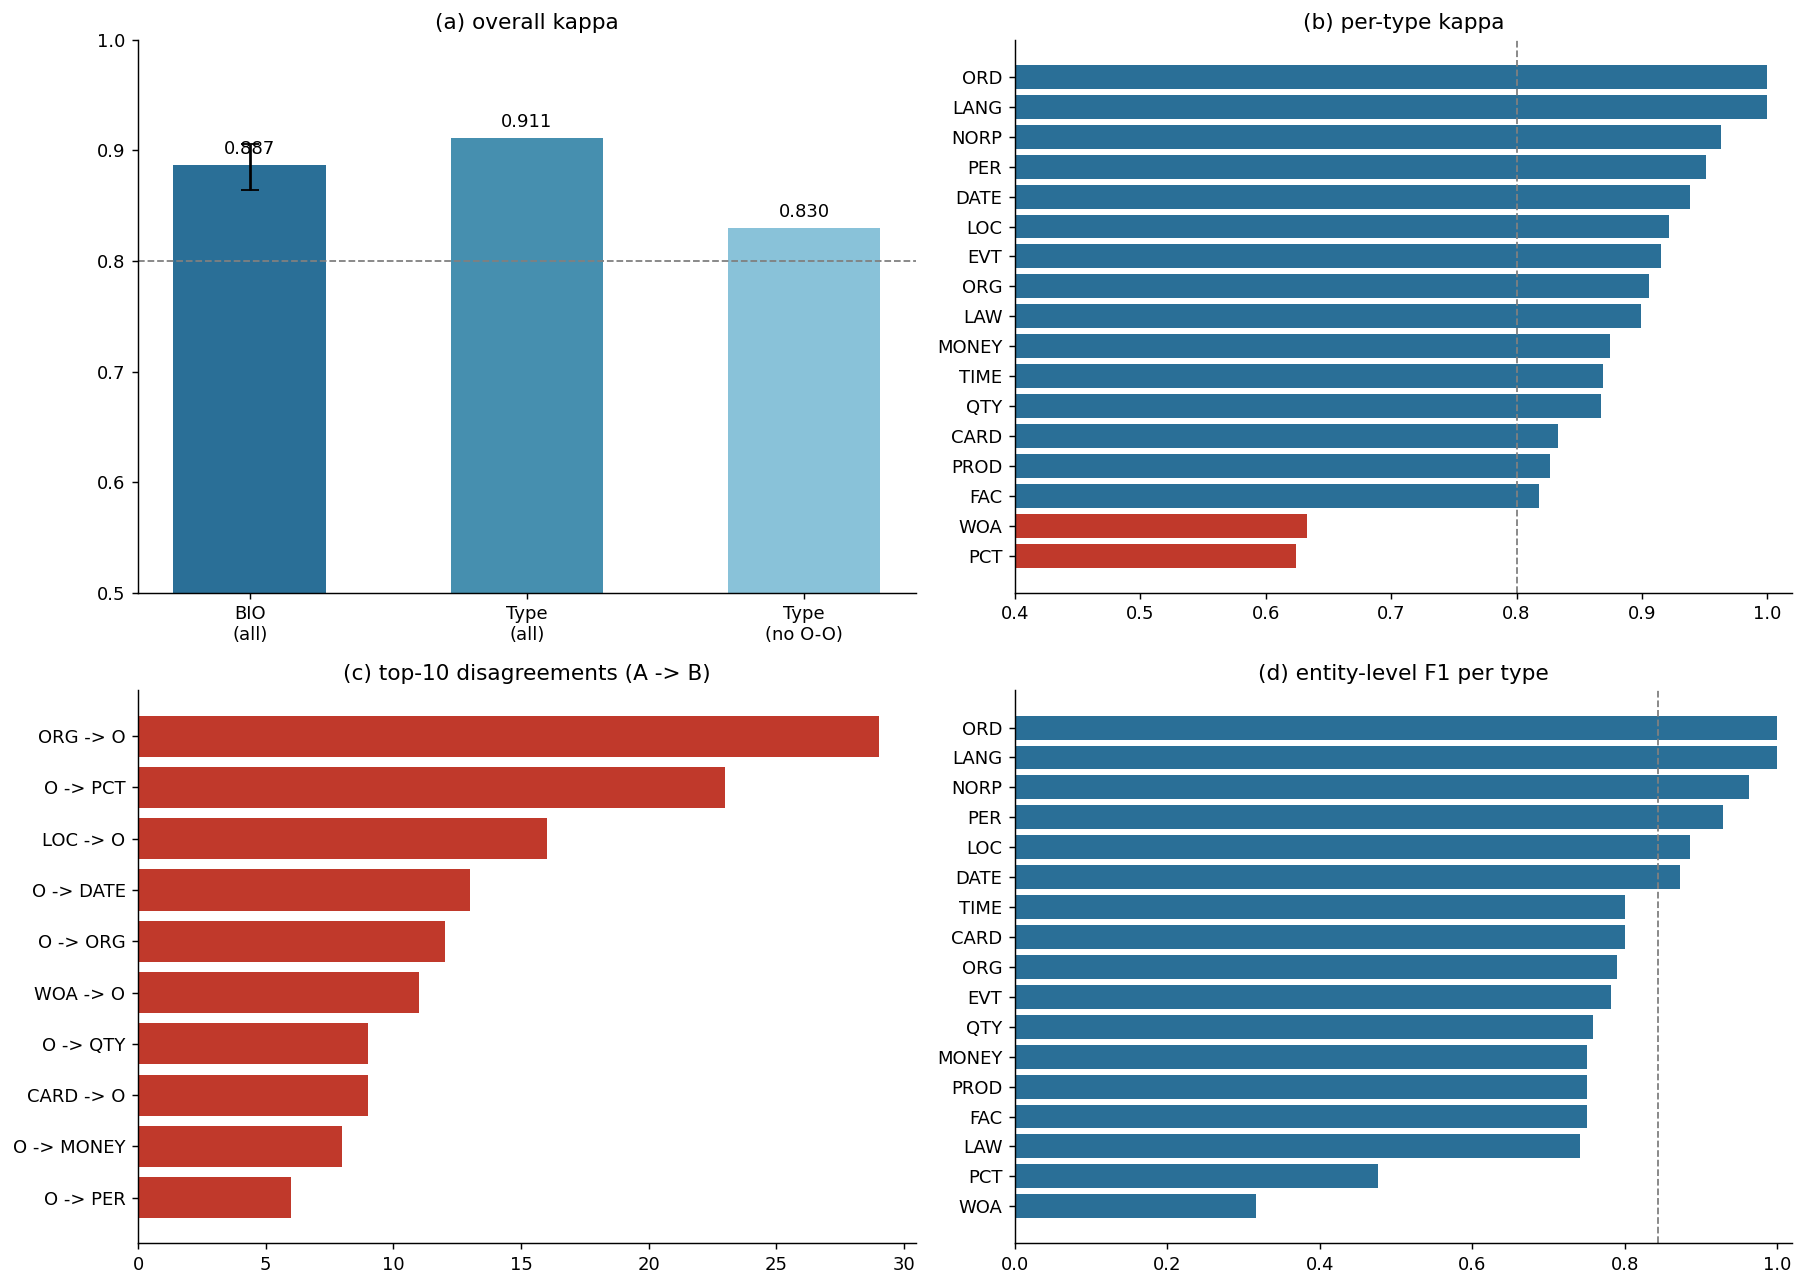

In [19]:
# CELL 6 - one-page summary figure for the paper (2x2)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# (a) overall
ax = axs[0, 0]
ax.bar(["BIO\n(all)", "Type\n(all)", "Type\n(no O-O)"], vals, color=["#2a6f97", "#468faf", "#89c2d9"], width=.55)
ax.errorbar(0, k_bio, yerr=[[k_bio - lo], [hi - k_bio]], fmt="none", ecolor="black", capsize=5)
for x, v in enumerate(vals): ax.text(x, v + .01, f"{v:.3f}", ha="center")
ax.axhline(.8, ls="--", c="gray", lw=1); ax.set_ylim(.5, 1); ax.set_title("(a) overall kappa")

# (b) per type
ax = axs[0, 1]
ax.barh([r[0] for r in rows], [r[1] for r in rows],
        color=["#c0392b" if r[1] < .7 else "#2a6f97" for r in rows])
ax.axvline(.8, ls="--", c="gray", lw=1); ax.set_xlim(.4, 1.02); ax.set_title("(b) per-type kappa")

# (c) disagreements
ax = axs[1, 0]
top = sorted([(labels[i], labels[j], cm2[i, j]) for i in range(len(labels)) for j in range(len(labels)) if cm2[i, j]],
             key=lambda x: -x[2])[:10][::-1]
ax.barh([f"{x} -> {y}" for x, y, _ in top], [c for *_, c in top], color="#c0392b")
ax.set_title("(c) top-10 disagreements (A -> B)")

# (d) entity f1
ax = axs[1, 1]
ax.barh([r[0] for r in res], [r[3] for r in res], color="#2a6f97")
ax.axvline(.844, ls="--", c="gray", lw=1); ax.set_xlim(0, 1.02); ax.set_title("(d) entity-level F1 per type")

plt.tight_layout(); plt.savefig("fig_summary.png", dpi=300, bbox_inches="tight"); plt.show()